# Train RT-DETR (or YOLO) on SAM-Relabeled Dataset

This notebook trains a detection model on the SAM-relabeled dataset from notebook 02.

**Default**: RT-DETR-l (DETR-based, good for aerial images)
**Alternative**: YOLO11 (faster, easier to train)

**Hardware note**: Training on Apple Silicon (MPS) works but is slow. For serious training, use a GPU (Colab, cloud, or local NVIDIA).


In [25]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import cv2
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO, RTDETR

from helpers.ntbk_utils import load_data_yaml, draw_boxes

plt.rcParams['figure.figsize'] = (12, 8)


In [29]:
# Configuration
MODEL_TYPE = "yolo"  # "rtdetr" or "yolo"
MODEL_SIZE = "m"  # For RT-DETR: "l", "x"; For YOLO: "n", "s", "m", "l", "x"

# Dataset
DATA_DIR = Path("../data/sam_labels")
YAML_PATH = DATA_DIR / "data.yaml"

# Training hyperparameters
EPOCHS = 50
BATCH_SIZE = 8  # Reduce if OOM on MPS
IMG_SIZE = 640
TEST_IMG_SIZE = 1280  # inference-only imgsz; training config untouched
PATIENCE = 10  # Early stopping

# Output
PROJECT_DIR = Path("runs/runs/")
PROJECT_DIR.mkdir(exist_ok=True)
RUN_NAME = f"{MODEL_TYPE}_{MODEL_SIZE}_train"
RESULTS_DIR = PROJECT_DIR / RUN_NAME
BEST_MODEL_PATH = RESULTS_DIR / "weights" / "best.pt"

data_cfg = load_data_yaml(YAML_PATH)
print(f"Model: {MODEL_TYPE}-{MODEL_SIZE}")
print(f"Dataset: {YAML_PATH}")
print(f"Classes: {data_cfg['names']}")
print(f"Epochs: {EPOCHS}, Batch: {BATCH_SIZE}, Img size: {IMG_SIZE}")


Model: yolo-m
Dataset: ../data/sam_labels/data.yaml
Classes: ['PMT', 'articulated-bus', 'bus', 'car', 'freight', 'motorbike', 'small bus', 'truck']
Epochs: 50, Batch: 8, Img size: 640


In [16]:
# Check for existing best.pt
SKIP_TRAINING = BEST_MODEL_PATH.exists()

if SKIP_TRAINING:
    print(f"\nFound existing model: {BEST_MODEL_PATH}")
    print("Loading existing model (skipping training)...")
    if MODEL_TYPE == "rtdetr":
        model = RTDETR(str(BEST_MODEL_PATH))
    else:
        model = YOLO(str(BEST_MODEL_PATH))
    print("Model loaded successfully.")
else:
    print(f"\nNo existing model found at {BEST_MODEL_PATH}")
    print("Will train a new model.")



Found existing model: runs/runs/yolo_m_train/weights/best.pt
Loading existing model (skipping training)...
Model loaded successfully.


In [6]:
# Train
print("Starting training...")
print(f"Device: {model.device}")

results = model.train(
    data=str(YAML_PATH),
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    imgsz=IMG_SIZE,
    patience=PATIENCE,
    project=str(PROJECT_DIR),
    name=f"{MODEL_TYPE}_{MODEL_SIZE}_train",
    exist_ok=True,
    pretrained=True,
    optimizer="auto",
    lr0=0.001,
    lrf=0.01,
    momentum=0.9,
    weight_decay=0.0005,
    warmup_epochs=3,
    warmup_momentum=0.8,
    box=7.5,
    cls=0.5,
    dfl=1.5,
    amp=True,
    verbose=True,
)

print("\nTraining complete!")
print(f"Results saved to: {PROJECT_DIR / f'{MODEL_TYPE}_{MODEL_SIZE}_train'}")


Starting training...
Device: cpu
New https://pypi.org/project/ultralytics/8.4.164 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.158 🚀 Python-3.11.15 torch-2.14.0 CPU (Apple M5)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../data/sam_labels/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, m

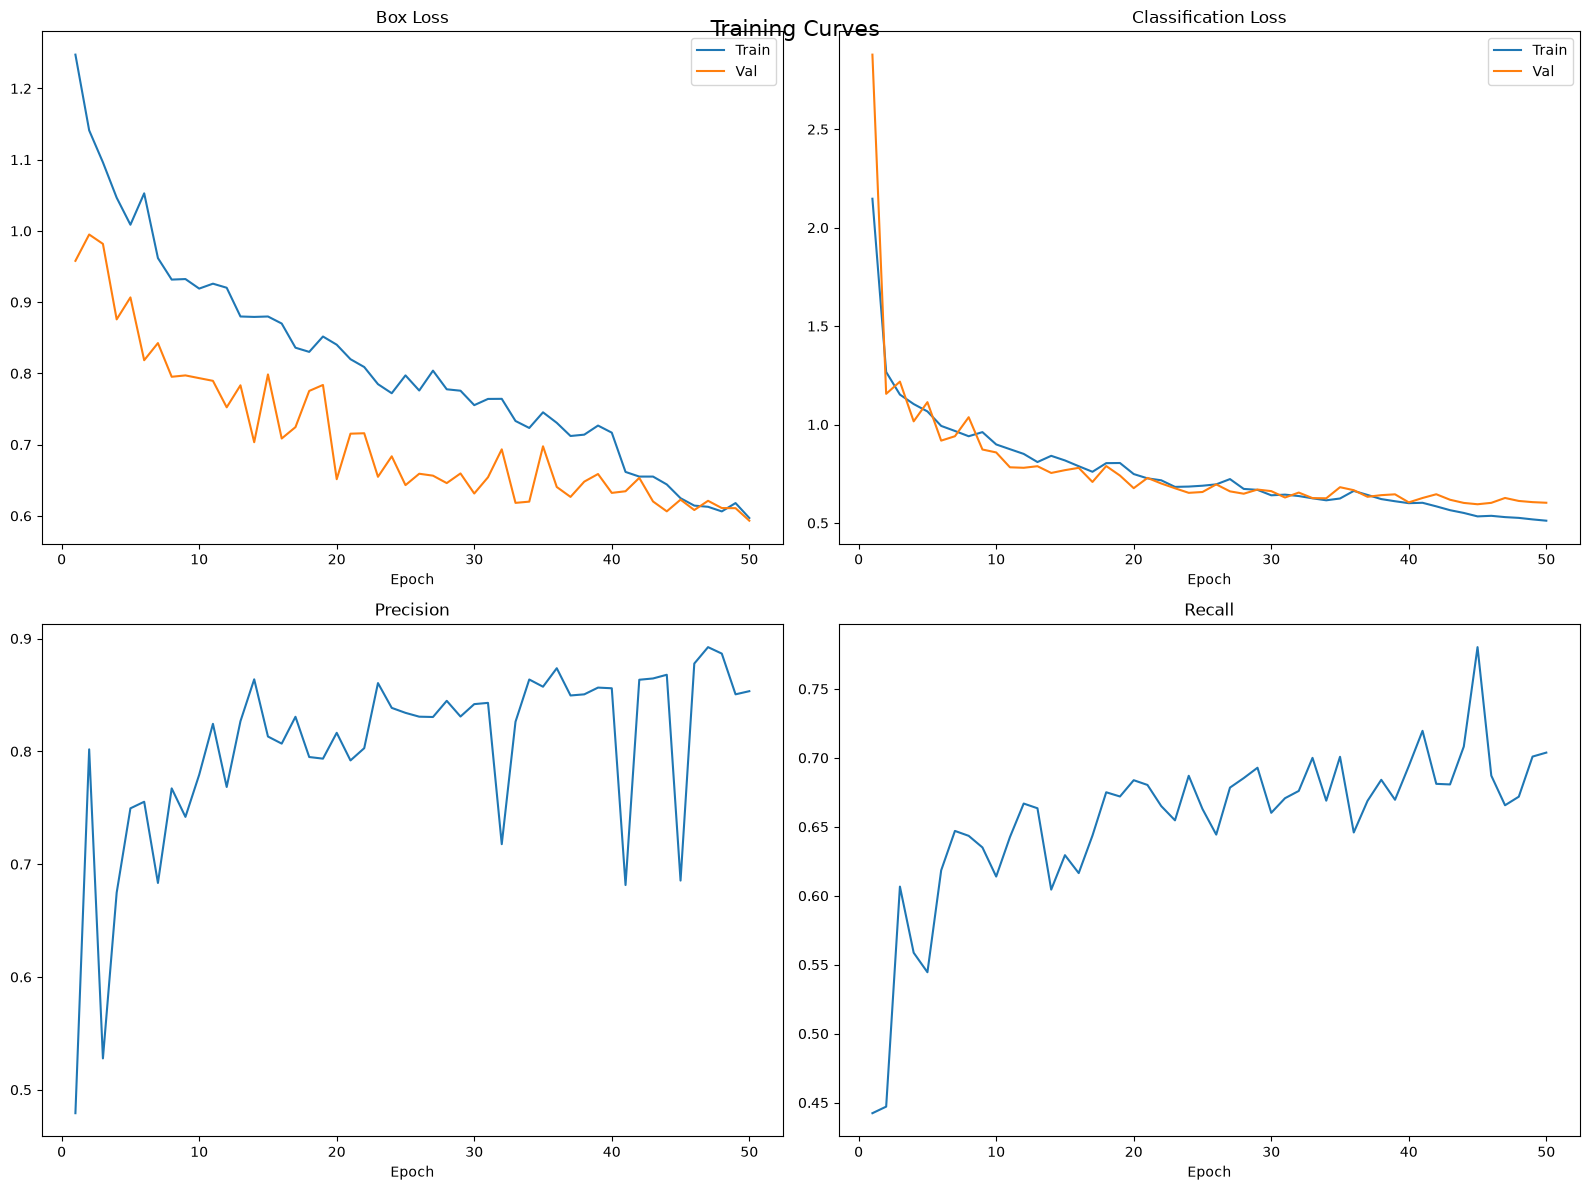

In [22]:
# Visualize training results
results_csv = RESULTS_DIR / "results.csv"

if results_csv.exists():
    df = pd.read_csv(results_csv)
    # Clean column names (remove leading/trailing spaces)
    df.columns = df.columns.str.strip()

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Box loss
    if "train/box_loss" in df.columns:
        axes[0, 0].plot(df["epoch"], df["train/box_loss"], label="Train")
        if "val/box_loss" in df.columns:
            axes[0, 0].plot(df["epoch"], df["val/box_loss"], label="Val")
        axes[0, 0].set_title("Box Loss")
        axes[0, 0].set_xlabel("Epoch")
        axes[0, 0].legend()

    # Classification loss
    if "train/cls_loss" in df.columns:
        axes[0, 1].plot(df["epoch"], df["train/cls_loss"], label="Train")
        if "val/cls_loss" in df.columns:
            axes[0, 1].plot(df["epoch"], df["val/cls_loss"], label="Val")
        axes[0, 1].set_title("Classification Loss")
        axes[0, 1].set_xlabel("Epoch")
        axes[0, 1].legend()

    # Precision
    if "metrics/precision(B)" in df.columns:
        axes[1, 0].plot(df["epoch"], df["metrics/precision(B)"])
        axes[1, 0].set_title("Precision")
        axes[1, 0].set_xlabel("Epoch")

    # Recall
    if "metrics/recall(B)" in df.columns:
        axes[1, 1].plot(df["epoch"], df["metrics/recall(B)"])
        axes[1, 1].set_title("Recall")
        axes[1, 1].set_xlabel("Epoch")

    plt.tight_layout()
    plt.suptitle("Training Curves", fontsize=16, y=0.98)
    plt.show()
else:
    print(f"No results.csv found at {results_csv}")


In [23]:
# Validate on test set
print("Running validation on test set...")

val_results = model.val(
    data=str(YAML_PATH),
    split="test",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    verbose=True,
)

print("\n" + "="*60)
print("VALIDATION RESULTS")
print("="*60)
print(f"mAP@0.5: {val_results.box.map50:.4f}")
print(f"mAP@0.5:0.95: {val_results.box.map:.4f}")
print(f"Precision: {val_results.box.mp:.4f}")
print(f"Recall: {val_results.box.mr:.4f}")


Running validation on test set...
Ultralytics 8.4.158 🚀 Python-3.11.15 torch-2.14.0 CPU (Apple M5)
YOLO11m summary (fused): 125 layers, 20,036,200 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1088.5±391.9 MB/s, size: 351.5 KB)
val: Scanning /Users/benedict/Workspace/yolo_train/aerial_images/test/labels... 440 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 440/440 5.6Kit/s 0.1s
val: New cache created: /Users/benedict/Workspace/yolo_train/aerial_images/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 55/55 1.5it/s 37.2s0.7ss
                   all        440      20798      0.687      0.486      0.549      0.386
                   PMT          4          5          0          0          0          0
       articulated-bus         87        144      0.396      0.549      0.566      0.426
                   bus        286        977      0.797      0.938      0.956   

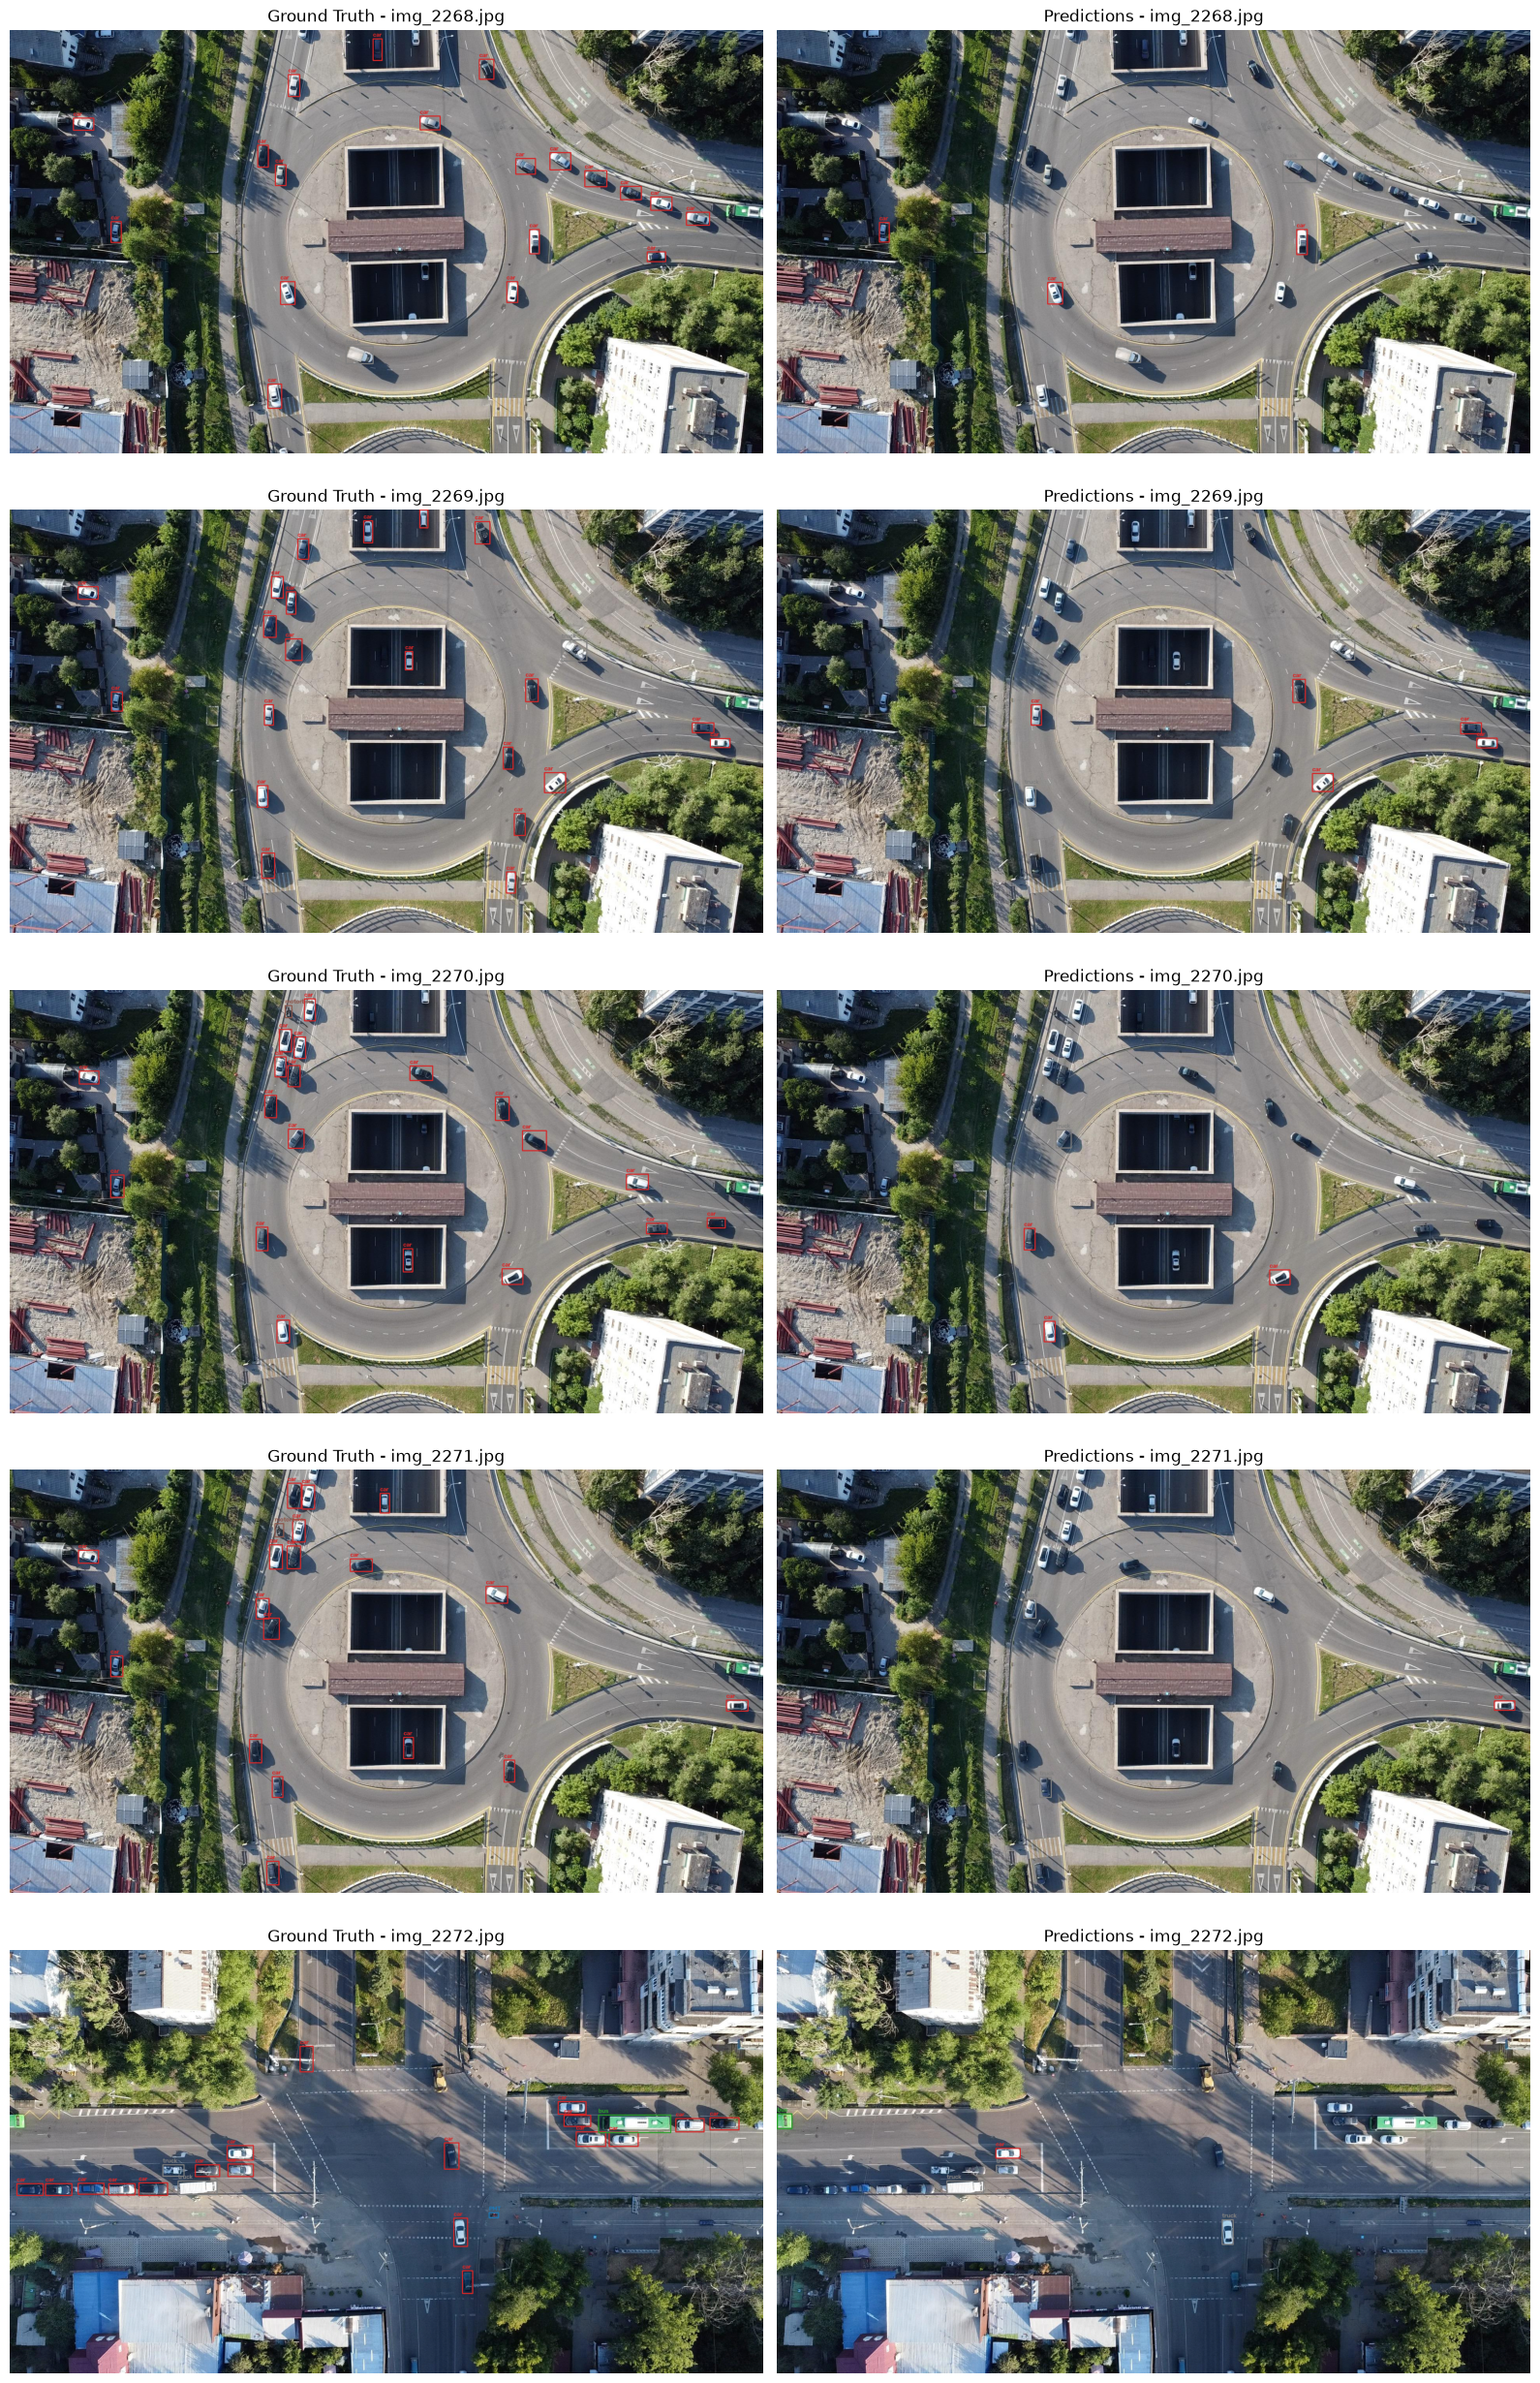

In [31]:
# Visualize predictions on test images
# Use original aerial_images/test since data/sam_labels only has train/valid
test_img_dir = Path("../aerial_images/test/images")
test_label_dir = Path("../aerial_images/test/labels")
test_images = sorted(test_img_dir.glob("*.jpg"))[:5]

fig, axes = plt.subplots(len(test_images), 2, figsize=(16, 5 * len(test_images)))
if len(test_images) == 1:
    axes = axes.reshape(1, -1)

for i, img_path in enumerate(test_images):
    img = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Load GT
    label_path = test_label_dir / (img_path.stem + ".txt")
    gt_boxes = []
    h, w = img.shape[:2]
    if label_path.exists():
        with open(label_path) as f:
            for line in f:
                parts = line.strip().split()
                cls = int(parts[0])
                xc, yc, bw, bh = map(float, parts[1:5])
                x1 = (xc - bw / 2) * w
                y1 = (yc - bh / 2) * h
                x2 = (xc + bw / 2) * w
                y2 = (yc + bh / 2) * h
                gt_boxes.append({"class": cls, "bbox": [x1, y1, x2, y2]})
    
    # Predict
    results = model(img_rgb, imgsz=640, verbose=False)
    pred_boxes = []
    for r in results:
        for box in r.boxes:
            cls_id = int(box.cls[0])
            conf = float(box.conf[0])
            if conf < 0.25:
                continue
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
            pred_boxes.append({"class": cls_id, "bbox": [x1, y1, x2, y2]})
    
    axes[i, 0].imshow(draw_boxes(img_rgb, gt_boxes, data_cfg["names"]))
    axes[i, 0].set_title(f"Ground Truth - {img_path.name}")
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(draw_boxes(img_rgb, pred_boxes, data_cfg["names"]))
    axes[i, 1].set_title(f"Predictions - {img_path.name}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()